# Tensor và autograd

Một nhóm học sinh muốn dự đoán thời gian chạy của lời giải từ ba đặc trưng: số đỉnh, số cạnh và số truy vấn. Trong C++, có thể lưu dữ liệu bằng `vector<array<double, 3>>`. Sang PyTorch, cùng bảng ấy trở thành tensor. Điều mới không chỉ là cú pháp: PyTorch còn ghi lại phép tính để trả lời câu hỏi “nên chỉnh mỗi trọng số bao nhiêu để dự đoán bớt sai?”. Bài này nối mảng nhiều chiều với đồ thị tính toán, rồi kiểm một gradient bằng tay trước khi giao việc cho autograd.

> **Mục tiêu sau bài này**
>
> - Đọc shape theo ý nghĩa từng chiều và dự đoán shape trước khi chạy code.
> - Phân biệt phép nhân từng phần tử, nhân ma trận, reshape và hoán đổi chiều.
> - Tính gradient của một biểu thức nhỏ, kiểm autograd và xóa gradient đúng lúc.
> - Phân biệt `detach`, `no_grad`, bản sao dữ liệu và chuyển thiết bị CPU/GPU.

## Từ mảng C++ tới tensor

Tensor là một khối số có shape, kiểu dữ liệu (dtype) và nơi lưu (device). Một số có shape `()`, một vector ba số có shape `(3,)`, bảng hai hàng ba cột có shape `(2, 3)`. Ba thuộc tính ấy là phần hợp đồng đầu vào của phép tính, giống kích thước mảng và kiểu số trong một lời giải CP. Tensor không tự biết chiều nào là học sinh, token hay đặc trưng; người viết phải đặt ý nghĩa đó.

Trọng số và đặc trưng thường dùng `float32`; mã lớp hoặc token ID dùng `int64`, còn gọi là `torch.long`. Tensor số nguyên không thể đặt `requires_grad=True`, vì đạo hàm chỉ có nghĩa trên số thực. `torch.tensor` suy dtype từ dữ liệu, nên chỉ một dấu chấm thập phân cũng đổi kiểu của cả tensor. Ví dụ dưới dùng số nhỏ để tính tay được: một bảng hai mẫu, chiếu sang hai đặc trưng mới.

In [ ]:
import torch

torch.set_num_threads(1)
torch.manual_seed(7)
X = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
W = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
b = torch.tensor([0.5, -0.5])
Y = X @ W + b
print(tuple(X.shape), X.dtype, X.device)
print(Y.tolist())
print(torch.tensor([1, 2, 3]).dtype, torch.tensor([1., 2., 3.]).dtype)

(2, 3) torch.float32 cpu
[[4.5, 4.5], [10.5, 10.5]]
torch.int64 torch.float32


Dòng đầu cho cả shape, dtype và device. Dòng thứ hai gồm hai hàng vì ta vẫn có hai mẫu. Với hàng đầu, đầu ra thứ nhất là $1+3+0.5=4.5$; đầu ra thứ hai là $2+3-0.5=4.5$. Bias `(2,)` được cộng vào từng hàng. `@` gộp chiều đặc trưng, còn `X * X` chỉ bình phương từng ô. Dòng cuối cho thấy dtype đi theo dữ liệu: `[1, 2, 3]` thành `int64`, `[1., 2., 3.]` thành `float32`.



| Đại lượng | Ý nghĩa | Shape |
|---|---|---|
| `X` | $B$ mẫu, mỗi mẫu $d$ đặc trưng | `(B, d)` |
| `W` | $d$ đầu vào thành $h$ đầu ra | `(d, h)` |
| `b` | Bias cho từng đầu ra | `(h,)` |
| `X @ W + b` | Đặc trưng mới của từng mẫu | `(B, h)` |

**Hỏi nhanh.** `X` có shape `(8, 3)`, `W` có shape `(3, 5)`. `X @ W` có shape gì?

- A. `(3, 3)`
- B. `(5, 8)`
- C. `(8, 5)`
- D. `(8, 3, 5)`

<details><summary>Đáp án</summary>

C. `(8, 5)`

Nhân ma trận gộp mất chiều 3 ở giữa, giữ số hàng 8 của `X` và số cột 5 của `W`. Chiều batch không biến mất. `(3, 3)` là lấy nhầm hai chiều bị gộp. `(5, 8)` là shape của `W.T @ X.T`. `(8, 3, 5)` là kết quả của `X[:, :, None] * W` khi chưa cộng theo chiều 3.

</details>

## Shape đúng phải đi cùng ý nghĩa đúng

Khi xử lý chuỗi, tensor thường là `(B, L, d)`: batch, độ dài, đặc trưng. `reshape` chia lại cách nhìn một dãy phần tử; nó không đổi thứ tự logic của dãy. `transpose` hoặc `permute` mới hoán đổi các trục. Đây giống khác biệt giữa đánh lại chỉ số của mảng một chiều và chuyển vị thật một bảng hai chiều.

In [ ]:
A = torch.arange(6).reshape(2, 3)
print(A.tolist())
print(A.reshape(3, 2).tolist())
print(A.transpose(0, 1).tolist())
print(A.unsqueeze(0).shape, A.sum(dim=1).shape)

[[0, 1, 2], [3, 4, 5]]
[[0, 1], [2, 3], [4, 5]]
[[0, 3], [1, 4], [2, 5]]
torch.Size([1, 2, 3]) torch.Size([2])


So hai bảng `(3, 2)`: reshape gom hai phần tử liên tiếp thành một hàng; transpose lấy các cột cũ làm hàng mới. Shape bằng nhau không bảo đảm dữ liệu mang cùng nghĩa. `unsqueeze(0)` thêm chiều batch kích thước 1; `sum(dim=1)` gộp ba cột của mỗi hàng. `squeeze(0)` chỉ xóa chiều 0 nếu nó bằng 1. Tránh dùng `squeeze()` không chỉ định chiều khi batch có thể bằng 1: chiều batch có thể mất ngoài ý muốn.

Vài quy ước gặp liên tục. Một batch ảnh màu có shape `(N, C, H, W)`: 32 ảnh RGB $64 \times 64$ là `(32, 3, 64, 64)`; thư viện ảnh thường trả `(H, W, 3)` nên phải `permute(2, 0, 1)` trước khi thêm chiều batch. Gộp theo chiều nào thì chiều đó biến mất: logits `(32, 10)` lấy nhãn bằng `argmax(dim=1)`, còn `dim=0` cho 10 số, mỗi số là ảnh có điểm cao nhất của một lớp. `torch.cat` nối theo một chiều có sẵn, hai tensor `(3, 4)` thành `(6, 4)`; `torch.stack` tạo chiều mới, thành `(2, 3, 4)`. `view` chỉ chạy khi dữ liệu nằm liền trong bộ nhớ theo đúng thứ tự; sau `transpose` phải dùng `reshape` hoặc `contiguous().view(...)`. Một số lớp mặc định thứ tự chiều riêng: `nn.LSTM` đọc `(L, B, d)` trừ khi đặt `batch_first=True`, nên đưa `(B, L, d)` vào vẫn chạy nhưng batch bị hiểu thành thời gian.



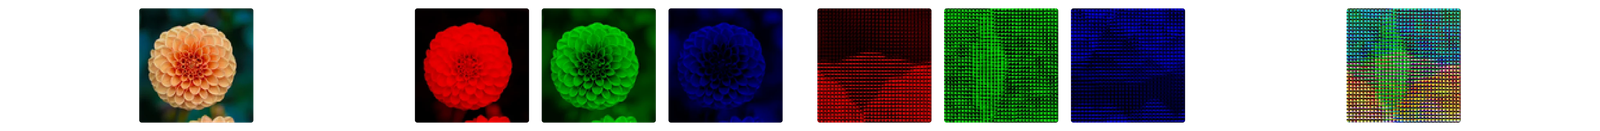

**Hỏi nhanh.** Bảng `A` có shape `(2, 3)`. Muốn đổi thành `(3, 2)` sao cho các cột cũ thành hàng mới, ta dùng gì?

- A. `A.reshape(3, 2)`
- B. `A.view(3, 2)`
- C. `A.unsqueeze(0)`
- D. `A.transpose(0, 1)`

<details><summary>Đáp án</summary>

D. `A.transpose(0, 1)`

`reshape` và `view` chỉ chia lại dãy phần tử theo đúng thứ tự cũ, nên với bảng `arange(6)`, hàng đầu vẫn là `[0, 1]`. `transpose` đổi chỗ hai trục, nên hàng đầu là `[0, 3]`, đúng là cột cũ. `unsqueeze(0)` chỉ thêm một chiều dài 1, ra `(1, 2, 3)`.

</details>

Broadcasting cũng cần kiểm. Phép cộng `(B, h)` với `(h,)` có ý nghĩa bias; phép trừ dự đoán `(B, 1)` với nhãn `(B,)` lại tạo `(B, B)`. Máy không hiểu ta định so từng mẫu. Đặt `assert prediction.shape == target.shape` trước loss hồi quy là một kiểm tra rẻ nhưng hữu ích. Shape chỉ đủ để chứng minh phép toán hợp lệ; tên chiều và thứ tự mẫu mới chứng minh phép toán đang giải bài toán cần giải.



**Hỏi nhanh.** Dự đoán `pred = [[1.], [2.]]`, shape `(2, 1)`, khớp đúng nhãn `target = [1., 2.]`, shape `(2,)`. Vậy mà `((pred - target) ** 2).mean()` lại in ra `0.5`. Vì sao?

- A. `float32` làm tròn 1 và 2 nên hiệu khác 0
- B. Phép trừ bị broadcast thành `(2, 2)`, so mọi cặp với nhau
- C. Nhãn phải có kiểu `long` thì phép trừ mới đúng
- D. `mean()` chia thêm cho chiều thứ hai

<details><summary>Đáp án</summary>

B. Phép trừ bị broadcast thành `(2, 2)`, so mọi cặp với nhau

Hiệu có shape `(2, 2)`, bằng `[[0, -1], [1, 0]]`: mỗi dự đoán bị trừ cho mọi nhãn. Trung bình bình phương là $2/4 = 0.5$, trong khi MSE đúng phải bằng 0. Số 1 và 2 được biểu diễn chính xác trong `float32`, và đổi kiểu hay cách chia cũng không tạo ra chiều thứ hai. Sửa bằng `pred.squeeze(-1)` kèm một dòng `assert`. Gặp hai shape này, `F.mse_loss` chỉ cảnh báo rồi vẫn trả về 0.5.

</details>

## Autograd lưu đường đi của phép tính

Trong bài linear regression, ta tự viết gradient. Với mạng nhiều lớp, biểu thức dài hơn nhưng mỗi phép cục bộ vẫn nhỏ: nhân, cộng, bình phương, ReLU. Autograd ghép đạo hàm cục bộ bằng quy tắc hàm hợp. Nó tính đạo hàm của phép tính đã thực hiện, không tìm công thức tối ưu và không tự sửa trọng số. So với sai phân hữu hạn ở bài 2.1, autograd cho đạo hàm chính xác và chỉ cần một lượt ngược cho mọi tham số, thay vì mỗi tham số một lượt chạy.

Hình dung một DAG trong CP. Forward tính các đỉnh theo thứ tự topo, lưu giá trị cần thiết. Backward đi ngược DAG, truyền độ nhạy của loss về các đầu vào. Nếu một biến góp mặt ở nhiều nhánh, các đóng góp gradient được **cộng**, giống cộng số đường đi từ các nhánh tới một đỉnh. PyTorch dựng DAG ngay trong lúc forward chạy và dựng lại ở mỗi lần forward (đồ thị động). Vì vậy `if` hay vòng lặp Python trong forward không cản autograd: backward đi theo đúng nhánh đã thực sự chạy. Mỗi phép lưu đúng thứ nó cần cho backward: sigmoid lưu chính đầu ra $y$ vì đạo hàm là $y(1-y)$, nên sửa $y$ tại chỗ như `y.add_(1)` sau forward sẽ làm backward báo lỗi.



**Hỏi nhanh.** Cho `x = torch.tensor(-3., requires_grad=True)`, rồi `y = 2 * x if x > 0 else x ** 2` và `y.backward()`. `x.grad` bằng bao nhiêu?

- A. `-6.0`, đạo hàm của nhánh `x ** 2`
- B. `2.0`, đạo hàm của nhánh `2 * x`
- C. `-2.0`, trung bình đạo hàm của hai nhánh
- D. Báo lỗi, vì graph phải cố định trước khi forward

<details><summary>Đáp án</summary>

A. `-6.0`, đạo hàm của nhánh `x ** 2`

Với $x = -3$, điều kiện sai, nên chỉ phép $x^2$ được chạy và ghi vào graph. Đạo hàm là $2x = -6$. Nhánh `2 * x` không chạy nên không có trong graph. Autograd không lấy trung bình các nhánh có thể xảy ra. Đồ thị được dựng trong lúc chạy, nên dùng `if` ngay trong forward là được.

</details>

## Ví dụ tính tay

Đặt $w=2$, $u=3w$, $J=(u-1)^2$. Forward cho $u=6$, $J=25$. Nếu tăng $w$ một lượng rất nhỏ, $u$ tăng ba lần lượng đó. Còn $J$ nhạy với $u$ một lượng $2(u-1)=10$. Vì vậy

$$\frac{dJ}{dw}=\frac{dJ}{du}\frac{du}{dw}=2(u-1)\cdot3=30.$$

Gradient dương nói rằng tăng $w$ một chút sẽ làm loss tăng tại điểm đang xét. Muốn đi xuống, gradient descent dùng $w\leftarrow w-\eta\,30$. Với $\eta=0.01$, một bước cho $w=1.7$; đó là phép cập nhật riêng, không thuộc `backward()`. Với nhiều biến, gradient gom các đạo hàm riêng: $f = x^2y + 3y$ tại $(1, 2)$ có gradient $(2xy,\ x^2 + 3) = (4, 4)$.

In [ ]:
w = torch.tensor(2., requires_grad=True)
u = 3 * w
J = (u - 1) ** 2
J.backward()
print(round(J.item(), 2), round(w.grad.item(), 2))
with torch.no_grad():
    w -= 0.01 * w.grad
print(round(w.item(), 2))

25.0 30.0
1.7


Hai số ở dòng đầu cần khớp $25$ và $30$ đã tính tay; dòng sau kiểm phép cập nhật $1.7$. `requires_grad=True` yêu cầu ghi đường tính toán liên quan. `w` là tensor lá do ta tạo trực tiếp; gradient được tích vào `w.grad`. Tensor trung gian không mặc định giữ `.grad`; điều đó không có nghĩa đường đạo hàm qua nó bị mất. `J` là scalar nên `backward()` biết bắt đầu từ độ nhạy 1. Với đầu ra vector, cần chọn cách gộp thành scalar hoặc cung cấp vector gradient phù hợp.

**Hỏi nhanh.** Vẫn $J = (3w - 1)^2$, nhưng tại $w = 0$. Gradient bằng bao nhiêu, và một bước gradient descent đẩy $w$ theo hướng nào?

- A. $6$, giảm $w$, tức đi ngược dấu gradient
- B. $6$, tăng $w$, tức đi theo dấu gradient
- C. $-6$, giảm $w$, tức đi theo dấu gradient
- D. $-6$, tăng $w$, tức đi ngược dấu gradient

<details><summary>Đáp án</summary>

D. $-6$, tăng $w$, tức đi ngược dấu gradient

Tại $w = 0$ thì $u = 0$, nên $\frac{dJ}{dw} = 2(u - 1)\cdot 3 = -6$. Gradient âm nghĩa là tăng $w$ thì loss giảm. Bước $w \leftarrow w - \eta\cdot(-6)$ làm $w$ tăng, với $\eta = 0.01$ thì $w = 0.06$. Hai phương án ra $6$ là quên dấu của $u - 1 = -1$. Đi theo dấu gradient là gradient ascent, làm loss tăng.

</details>

## Gradient được cộng dồn

PyTorch cộng gradient mới vào `.grad`. Cách này cho phép tích lũy nhiều microbatch, nhưng trong training loop bình thường ta phải xóa trước mỗi bước. Sau `backward()`, PyTorch giải phóng các giá trị trung gian của graph, nên mỗi lượt dưới đây có forward riêng:

In [ ]:
v = torch.tensor(2., requires_grad=True)
((3 * v - 1) ** 2).backward()
print(v.grad.item())
((3 * v - 1) ** 2).backward()
print(v.grad.item())
v.grad = None
((3 * v - 1) ** 2).backward()
print(v.grad.item())

30.0
60.0
30.0


Dãy $30,60,30$ cho thấy gradient cộng dồn và phép xóa đã hoạt động. Trong training loop, việc xóa do `optimizer.zero_grad(set_to_none=True)` đảm nhận. Gọi `backward()` hai lần trên cùng một graph sẽ báo lỗi; đừng sửa bằng `retain_graph=True`: giữ graph tốn bộ nhớ, không xóa gradient cũ, và graph cũ vẫn mô tả trọng số cũ. Mỗi bước huấn luyện cần forward mới rồi backward mới.



**Hỏi nhanh.** Một bạn tính `loss` một lần trước vòng lặp, rồi mỗi epoch gọi `loss.backward()` và `optimizer.step()`. Sang epoch thứ hai thì báo `RuntimeError: Trying to backward through the graph a second time`. Sửa thế nào?

- A. Thêm `retain_graph=True` để graph không bị giải phóng
- B. Gọi `optimizer.zero_grad()` trước lần `backward()` thứ hai
- C. Đưa forward và phép tính `loss` vào trong vòng lặp
- D. Đổi thành `loss.detach().backward()` để tách khỏi graph cũ

<details><summary>Đáp án</summary>

C. Đưa forward và phép tính `loss` vào trong vòng lặp

Graph của `loss` bị giải phóng sau lần backward đầu tiên. Kể cả giữ lại bằng `retain_graph=True`, graph ấy vẫn được tính từ trọng số ban đầu, nên không cho gradient tại trọng số mới. `zero_grad()` chỉ xóa `.grad`, không dựng lại graph. `loss.detach()` không còn nối với tham số, nên backward báo một lỗi khác. Forward lại ở mỗi bước thì vừa có graph mới, vừa dùng đúng trọng số vừa cập nhật.

</details>

## Detach, no_grad và bản sao

Khi lưu dự đoán để tính metric, ta không muốn giữ cả đường tính toán. `detach()` tạo tensor không nối gradient về nguồn. Nó vẫn có thể dùng chung vùng nhớ với tensor gốc; muốn lưu snapshot độc lập, dùng `detach().clone()`. `no_grad()` tạm ngừng ghi graph cho các phép trong khối, thích hợp cho suy luận hoặc cập nhật thủ công. Nó không tự chuyển model sang `eval()`; chế độ layer sẽ học ở bài 3.4 và 3.6. Ngược lại, `eval()` cũng không tắt gradient; lúc đánh giá nên dùng cả hai.

Ta kiểm ý nghĩa “cắt đường gradient” bằng biểu thức $v^3$. Nếu giữ cả hai nhánh, đạo hàm tại $v=2$ là $3v^2=12$. Nếu tính $v^2$ rồi detach, hệ số 4 ấy được coi như hằng số:

In [ ]:
v.grad = None
square = v ** 2
frozen_square = square.detach()
(frozen_square * v).backward()
print(v.grad.item(), frozen_square.requires_grad)
snapshot = square.detach().clone()
print(snapshot.item())

4.0 False
4.0


Gradient 4 là đúng với **graph đã bị cắt**, dù giá trị forward vẫn bằng 8. Detach không phải thủ thuật sửa lỗi backward mà không đổi bài toán: nó có thể làm tham số trước điểm cắt không học được. Chuyển tensor cần gradient sang NumPy cũng nên viết `tensor.detach().cpu().numpy()` khi chỉ phục vụ phân tích. Với một số đơn lẻ như loss, `loss.item()` trả về số Python; ghi log bằng số này không giữ graph.

Cập nhật tham số bằng tay cũng đặt trong `no_grad()`: `with torch.no_grad(): w -= lr * w.grad`; viết thẳng thì PyTorch báo lỗi sửa tại chỗ một tensor lá cần gradient. Ngược lại, chạy forward trong `no_grad()` rồi gọi `loss.backward()` sẽ báo loss không có `grad_fn`. Detach còn được dùng có chủ đích: mang trạng thái ẩn của RNN sang đoạn văn bản sau bằng `hidden.detach()` (bài 3.8), hay viết `y = x + (x.round() - x).detach()` để forward ra `round(x)` còn backward coi như $y = x$ (straight-through estimator).



**Hỏi nhanh.** `w` bằng 2 và đã có `w.grad` bằng 30. Chạy `snap = w.detach()`, rồi `with torch.no_grad(): w -= 0.1 * w.grad`. `snap.item()` in ra gì?

- A. `2.0`, vì `snap` đã tách khỏi graph
- B. `2.0`, vì `no_grad` không làm đổi giá trị của `w`
- C. `-1.0`, vì `snap` dùng chung vùng nhớ với `w`
- D. Báo lỗi, vì tensor đã detach thì không đọc được

<details><summary>Đáp án</summary>

C. `-1.0`, vì `snap` dùng chung vùng nhớ với `w`

`detach()` chỉ tách khỏi graph, không sao chép dữ liệu. `snap` nhìn vào đúng vùng nhớ của `w`, nên phép trừ tại chỗ $2 - 0.1\cdot 30 = -1$ hiện ra ở cả hai. Muốn giữ lại giá trị 2 thì phải viết `w.detach().clone()`. `no_grad` chỉ ngừng ghi graph, phép cập nhật vẫn chạy. Tensor đã detach vẫn đọc và tính toán bình thường.

</details>

## Thiết bị và nơi lưu dữ liệu

GPU thực hiện nhiều phép số song song, nhưng mọi tensor trong một phép tính phải cùng device. Với tensor, `.to(device)` trả về **tensor mới** trên device đã chọn, nên phải gán lại: `X = X.to(device)`. Với model, `model.to(device)` chuyển tham số và buffer của module tại chỗ. Tensor tạo mới trong `forward`, như `torch.ones(...)`, mặc định nằm trên CPU; viết `device=x.device` hoặc `torch.ones_like` để nó theo dữ liệu, đừng ghi cứng `'cuda'`. Đoạn sau chọn CUDA khi có, nếu không thì dùng CPU; các dòng còn lại không phụ thuộc máy:

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
X_device = X.to(device)
linear = torch.nn.Linear(3, 2).to(device)
with torch.no_grad():
    result = linear(X_device)
print(str(device), tuple(result.shape))
print(result.detach().cpu().numpy().shape)

cpu (2, 2)
(2, 2)


Máy chạy bài không có CUDA nên dòng đầu in `cpu`; trên máy có CUDA hoạt động, cùng đoạn code chọn `cuda` mà không phải sửa dòng nào. Dòng hai đi theo đường thường dùng khi lấy kết quả ra phân tích: ngắt graph, chép về CPU, rồi mới sang NumPy. Tên GPU trong mô tả môi trường chưa đủ chứng minh CUDA dùng được; `torch.cuda.is_available()` cùng một batch chạy thử mới xác nhận. GPU cũng không tự nhanh hơn: với dữ liệu rất nhỏ, thời gian chép dữ liệu và khởi động có thể lớn hơn phần tính. Bài 3.7 có recipe đo thời gian mỗi bước trên máy CUDA.

**Hỏi nhanh.** Model đã gọi `model.to('cuda')`. Trong vòng lặp có dòng `X.to('cuda')`, không gán lại, rồi `model(X)`, và PyTorch báo các tensor nằm trên hai device khác nhau. Vì sao?

- A. `X.to` trả về một bản mới, còn `X` cũ vẫn ở CPU
- B. `model.to` cũng phải gán lại thì model mới chuyển
- C. Phải dùng `X.cuda()`, vì `.to` chỉ đổi dtype
- D. Batch quá nhỏ nên PyTorch giữ `X` ở CPU

<details><summary>Đáp án</summary>

A. `X.to` trả về một bản mới, còn `X` cũ vẫn ở CPU

Với tensor, `.to` không đổi tại chỗ, nên phải viết `X = X.to('cuda')`. Với module, `.to` chuyển tham số tại chỗ và trả về chính module, nên `model.to('cuda')` không gán lại vẫn đúng. `.to('cuda')` đổi được cả device lẫn dtype, và về device thì giống `.cuda()`. PyTorch không tự giữ batch nhỏ ở CPU.

</details>

## Bẫy cài đặt

Lỗi shape thường xuất hiện xa nơi tạo tensor. In shape tại ranh giới `dataset → model → loss`, rồi giảm về một batch để truy ra chiều sai. Nếu mô hình nhị phân cho `(B, 1)`, hãy dùng `squeeze(-1)` và nhãn `(B,)`; đừng xóa mọi chiều 1. Kiểm dtype của nhãn trước khi gọi loss và device trước nhân ma trận. Khi gradient bằng `None`, lần theo chỗ detach, no_grad, phép ép sang số Python hoặc tham số không tham gia forward.

Trong CP, một phép ép kiểu sai có thể âm thầm tràn số. Với AI, một broadcast sai có thể âm thầm đổi hàm mục tiêu. Vì vậy bộ kiểm nhỏ gồm shape, tính tay và gradient là phần tương đương với brute force để đối chiếu. Chỉ khi một mẫu nhỏ đúng mới tăng batch, thêm lớp và chuyển GPU.

**Hỏi nhanh.** Tính tay $J = (3w - 1)^2 + w$ tại $w = 2$ được $dJ/dw = 31$, nhưng autograd lại in `1.0`. Forward viết:
```py
u = torch.tensor(3 * w.item())
J = (u - 1) ** 2 + w
```
Nguyên nhân là gì?

- A. Tính tay sai, vì số hạng $+w$ chỉ đóng góp $1$
- B. `.item()` đổi sang số Python, cắt mất đường đi qua `u`
- C. `torch.tensor` tạo `u` kiểu `int64` nên mất đạo hàm
- D. Thiếu `retain_graph=True` để giữ nhánh đi qua `u`

<details><summary>Đáp án</summary>

B. `.item()` đổi sang số Python, cắt mất đường đi qua `u`

`w.item()` là số Python 2.0, nên `u` là một tensor mới, không nối gì với `w`. Autograd chỉ còn thấy số hạng $+w$ và trả về 1. Tính tay vẫn đúng: $2(u - 1)\cdot 3 + 1 = 31$. `3 * 2.0` là số thực nên `u` có kiểu `float32`. `retain_graph` chỉ giữ graph đã có, không nối lại được đường đã bị cắt. Viết `u = 3 * w` thì đường đạo hàm còn nguyên.

</details>

## Khi đi thi

- **In shape ở ranh giới.** In shape sau dataset, sau model và trước loss; đặt `assert pred.shape == target.shape` cho hồi quy. Dùng `squeeze(-1)`, không dùng `squeeze()` khi batch có thể bằng 1.
- **Kiểm dtype theo loss.** Nhãn lớp cho cross-entropy là `long`; nhãn hồi quy và nhãn của BCE là `float`. `torch.tensor` suy dtype từ dữ liệu, nên đọc dtype ngay khi tạo tensor từ list hay CSV.
- **Một batch trước khi tiêu ngân sách GPU.** Chạy forward và backward trên một batch: loss hữu hạn, gradient của mọi tham số cần học khác `None`, rồi mới chạy cả epoch.
- **Code không gắn với máy.** Đặt `device` một chỗ, chuyển model, input và nhãn bằng `.to(device)`; không gõ cứng `.cuda()`, để notebook vẫn chạy khi máy chấm chỉ có CPU.
- **Suy luận trong `no_grad`, ghi log bằng `.item()`.** Dự đoán cho submission đưa về `.detach().cpu()` trước khi ghép; loss ghi bằng `.item()` để không giữ graph qua hàng nghìn bước.

## Tóm tắt

Tensor là mảng kèm shape, dtype và device. Autograd ghi DAG của forward, rồi cộng gradient theo các đường ở backward. `backward()` chưa cập nhật trọng số; `.grad` cần xóa đúng chu kỳ. `detach()` cắt graph, `clone()` tạo bản sao, `.item()` lấy ra số Python, `no_grad()` ngừng ghi graph cho một khối. Những kiểm tra ấy giữ nguyên khi mạng trở nên phức tạp hơn.

## Kiểm tra cuối bài

**Câu 1.** Batch embedding `E` có shape `(4, 6, 8)`: 4 câu, mỗi câu 6 token, mỗi token 8 đặc trưng. Muốn mỗi câu có một vector bằng trung bình các token, ta gọi `E.mean(dim=?)`, và nhận được shape gì?

- A. `dim=0`, shape `(6, 8)`
- B. `dim=1`, shape `(4, 8)`
- C. `dim=1`, shape `(4, 1, 8)`
- D. `dim=2`, shape `(4, 6)`

<details><summary>Đáp án</summary>

B. `dim=1`, shape `(4, 8)`

Chiều token là chiều 1. Lấy trung bình theo chiều ấy thì còn `(4, 8)`, mỗi câu một vector 8 số. `dim=0` trộn 4 câu khác nhau. `dim=2` trộn các đặc trưng của từng token. `(4, 1, 8)` chỉ xuất hiện khi thêm `keepdim=True`.

</details>

**Câu 2.** `a = torch.tensor([1, 2, 3])` và `b = torch.Tensor([1, 2, 3])`. Hai tensor này có dtype gì?

- A. `a` là `float32`, `b` là `float32`
- B. `a` là `int64`, `b` là `int64`
- C. `a` là `int64`, `b` là `float32`
- D. `a` là `float32`, `b` là `int64`

<details><summary>Đáp án</summary>

C. `a` là `int64`, `b` là `float32`

`torch.tensor`, viết thường, suy dtype từ dữ liệu: toàn số nguyên thì thành `int64`. `torch.Tensor`, viết hoa, là hàm tạo của lớp, luôn dùng dtype mặc định `float32`. Vì vậy gọi `a.mean()` hay đặt `requires_grad=True` cho `a` đều báo lỗi. Khi cần số thực, hãy viết `[1., 2., 3.]` hoặc thêm `dtype=torch.float32`.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 129](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=49)

</details>

**Câu 3.** `x = torch.tensor([1., -2., 3.], requires_grad=True)`, `loss = (x ** 2).mean()`, rồi `loss.backward()`. `x.grad` bằng bao nhiêu, làm tròn hai chữ số?

- A. `[0.67, -1.33, 2.00]`
- B. `[2.00, -4.00, 6.00]`
- C. `[0.33, 1.33, 3.00]`
- D. `4.67`

<details><summary>Đáp án</summary>

A. `[0.67, -1.33, 2.00]`

$\text{loss} = \frac13\sum_i x_i^2$, nên $\partial\,\text{loss}/\partial x_i = \frac23 x_i$. `[2, -4, 6]` là gradient $2x$ của tổng bình phương: đổi từ tổng sang trung bình thì gradient bị chia cho số phần tử. `[0.33, 1.33, 3.00]` là $x_i^2/3$, nhầm giá trị với đạo hàm. `4.67` là chính loss, còn `.grad` thì luôn cùng shape với `x`.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 53](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=22)

</details>

**Câu 4.** Một model khai báo ba lớp `fc1`, `fc2`, `fc3` trong `__init__`, nhưng `forward` chỉ gọi `fc1` rồi `fc2`. Sau `loss.backward()`, `fc3.weight.grad` là gì?

- A. Tensor toàn 0, vì `fc3` không ảnh hưởng tới loss
- B. `None`, vì `fc3` không có trong đồ thị của forward
- C. Gradient bình thường, vì `fc3` có trong `model.parameters()`
- D. Báo lỗi lúc backward, vì có tham số không được dùng

<details><summary>Đáp án</summary>

B. `None`, vì `fc3` không có trong đồ thị của forward

Đồ thị tính toán ghi lại các phép **đã chạy** trong forward, không phải sơ đồ kiến trúc khai báo trong `__init__`. Backward chỉ đi qua các đỉnh của đồ thị, nên không chạm tới `fc3`. `.grad` của nó chưa từng được tạo, nên vẫn là `None`, không phải tensor 0. Có mặt trong `model.parameters()` chỉ có nghĩa là optimizer quản lý tham số ấy, và optimizer bỏ qua tham số có `.grad` bằng `None`. PyTorch không báo lỗi khi có tham số không dùng tới, nên lỗi quên nối một lớp rất dễ lọt. Kiểm `.grad is None` sau một batch thử là bắt được.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 54](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=22)

</details>

**Câu 5.** Huấn luyện full-batch trên dữ liệu cố định. Mỗi epoch gọi `optimizer.zero_grad()`, tính `loss`, gọi `loss.backward()`, nhưng quên `optimizer.step()`. Loss in ra qua các epoch sẽ thế nào?

- A. Giảm chậm, vì backward tự cập nhật với learning rate mặc định
- B. Tăng dần, vì gradient cộng dồn qua các epoch
- C. Không đổi, vì backward chỉ tính gradient
- D. Thành NaN, vì graph cũ không được giải phóng

<details><summary>Đáp án</summary>

C. Không đổi, vì backward chỉ tính gradient

`backward()` tính đạo hàm rồi cộng vào `.grad`, còn tham số chỉ thay đổi ở `optimizer.step()`. Không có step, mỗi epoch tính lại cùng một loss trên cùng dữ liệu và cùng trọng số, nên số in ra lặp lại y hệt. Gradient không cộng dồn vì đã có `zero_grad()`, và graph được giải phóng sau mỗi lần backward. Loss đứng yên tuyệt đối ngay từ epoch đầu là dấu hiệu nên kiểm vòng lặp trước khi đổi learning rate.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 120](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=46)

</details>

**Câu 6.** Một bạn khởi tạo `w = torch.randn(3, requires_grad=True) * 0.01`, tính loss rồi gọi `backward()`. `w.grad` là `None`, và PyTorch đưa ra cảnh báo. Vì sao?

- A. `w` được sinh ra từ một phép nhân, không phải tensor lá
- B. Nhân với 0.01 làm mất `requires_grad` của `w`
- C. `torch.randn` tạo tensor không hỗ trợ đạo hàm
- D. Gradient quá nhỏ nên bị làm tròn thành `None`

<details><summary>Đáp án</summary>

A. `w` được sinh ra từ một phép nhân, không phải tensor lá

`requires_grad=True` được đặt cho tensor do `randn` tạo ra. Còn `w` là tensor trung gian sinh từ phép nhân: `w.is_leaf` là `False`, dù `w.requires_grad` vẫn là `True`. Gradient chỉ được giữ ở tensor lá, nên `w.grad` là `None`, và `torch.optim` cũng từ chối những tham số không phải lá. Sửa bằng `w = (torch.randn(3) * 0.01).requires_grad_()`. Gradient nhỏ thì vẫn là một con số, không thành `None`.

</details>

**Câu 7.** `loss` là tensor 0 chiều, `logits` là tensor `(32, 10)`, cả hai còn nối với graph. Ta muốn (a) ghi loss vào log dưới dạng số Python, và (b) giữ `logits` ở dạng tensor nhưng không giữ graph. Gọi gì?

- A. (a) `loss.detach()`, (b) `logits.detach()`
- B. (a) `loss.detach()`, (b) `logits.item()`
- C. (a) `loss.item()`, (b) `logits.item()`
- D. (a) `loss.item()`, (b) `logits.detach()`

<details><summary>Đáp án</summary>

D. (a) `loss.item()`, (b) `logits.detach()`

`.item()` đổi một tensor **chỉ có một phần tử** thành số Python, hợp với loss. Gọi trên `logits` có 320 phần tử sẽ báo lỗi. `.detach()` trả về tensor cùng shape, không nối với graph và dùng chung vùng nhớ, hợp với `logits`. `loss.detach()` thì vẫn là tensor, chưa phải số Python.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 145](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=55)

</details>

**Câu 8.** Hàm dự đoán tập test chạy `preds.append(model(xb))` cho 2000 batch trên GPU. Bộ nhớ tăng dần rồi báo out of memory, dù batch nào cũng rất nhỏ. Sửa thế nào?

- A. Gọi `optimizer.zero_grad()` sau mỗi batch dự đoán
- B. Giảm batch size xuống một nửa rồi chạy lại
- C. Gọi `torch.cuda.empty_cache()` sau mỗi batch
- D. Chạy trong `torch.no_grad()`, và lưu kết quả bằng `.cpu()`

<details><summary>Đáp án</summary>

D. Chạy trong `torch.no_grad()`, và lưu kết quả bằng `.cpu()`

Không có `no_grad`, mỗi output còn nối với graph và các activation trung gian của batch ấy trên GPU. Danh sách `preds` giữ lại cả 2000 graph. `no_grad` không ghi graph, còn `.cpu()` đưa kết quả ra khỏi GPU. `zero_grad()` chỉ xóa `.grad` của tham số. Giảm batch chỉ làm chậm thời điểm hết bộ nhớ. `empty_cache()` chỉ trả lại phần bộ nhớ đệm chưa dùng, không giải phóng được tensor còn đang được giữ.

</details>

**Câu 9.** `X` có shape `(64, 10)`: 64 mẫu, mỗi mẫu 10 đặc trưng. Để trừ mỗi hàng cho trung bình của chính hàng đó, một bạn viết `m = X.mean(dim=1)` rồi `X - m`. Kết quả thế nào?

- A. Báo lỗi, vì `(64, 10)` và `(64,)` không broadcast được
- B. Chạy đúng, mỗi hàng trừ trung bình của chính nó
- C. Chạy được, nhưng ra `(64, 64)`, so mọi cặp mẫu
- D. Chạy được, nhưng trừ trung bình theo từng cột

<details><summary>Đáp án</summary>

A. Báo lỗi, vì `(64, 10)` và `(64,)` không broadcast được

Broadcasting so shape từ chiều cuối: `(64, 10)` với `(64,)` đặt 10 đối diện 64. Hai số khác nhau và không số nào bằng 1, nên phép trừ báo lỗi. Sửa bằng `X.mean(dim=1, keepdim=True)`, có shape `(64, 1)`, để chiều 1 được kéo ra thành 10 cột. `(64, 64)` chỉ xuất hiện khi một vế có chiều bằng 1, như bẫy `(B, 1)` trừ `(B,)`. Nguy hiểm hơn là khi số mẫu bằng số đặc trưng, chẳng hạn `X` có shape `(10, 10)`: phép trừ chạy mà không báo lỗi, nhưng cột $j$ lại bị trừ trung bình của hàng $j$.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 104](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=41)

</details>

**Câu 10.** Model có tham số trên CUDA, `X` đang ở CPU, và `y` là nhãn lớp kiểu `long` dùng cho cross-entropy. Muốn train một batch trên CUDA, ta làm gì?

- A. Chỉ chuyển `X`, vì hàm loss tự chuyển `y` theo input
- B. Chuyển cả `X` lẫn `y` tới device của model
- C. Gọi `model.eval()` để tự đồng bộ device của input
- D. Đổi `y` sang `float` để loss nhận nhãn ở CPU

<details><summary>Đáp án</summary>

B. Chuyển cả `X` lẫn `y` tới device của model

Input, target và tham số trong cùng một phép tính phải nằm trên cùng device: `X = X.to(device)` và `y = y.to(device)`. Hàm loss không tự chuyển `y`. `eval()` đổi chế độ của các lớp, không đổi device. Đổi `y` sang `float` không đổi device, mà với cross-entropy theo chỉ số lớp còn làm sai kiểu: nhãn phải giữ ở `long`.

</details>

## Đọc thêm

- [PyTorch — Automatic Differentiation](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html): đọc về graph động, gradient cộng dồn và cách tắt theo dõi.
- [D2L — Forward/Backward Propagation](https://d2l.ai/chapter_multilayer-perceptrons/backprop.html): xem đồ thị tính toán như cầu nối từ đạo hàm một biến sang mạng.
- [PyTorch 2.9 — Tensor](https://docs.pytorch.org/docs/2.9/tensors.html): tra shape, dtype, device và các thao tác tensor trước khi ghép model lớn.

Nguồn ảnh: ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0).